# OTT Streaming Content Trend Analysis
Platforms: Netflix, Amazon Prime Video, Disney+ Hotstar.

**Data limitation:** This project uses a generated synthetic 600-row dataset. It is not an official or scraped catalog from the named services. `imdb_score_demo` is simulated, not a real IMDb score.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("ott_streaming_catalog_synthetic.csv")
df.head()

,content_id,title,platform,content_type,genre,country,release_year,date_added,content_rating,imdb_score_demo,duration,duration_value,seasons
0,OTT0001,The Last Signal 001,Netflix,Movie,Action,India,2012,2023-04-01,U/A 13+,6.3,92 min,92,0
1,OTT0002,Code Red 002,Netflix,TV Show,Drama,United Kingdom,2021,2026-08-01,TV-MA,6.4,4 Seasons,4,4
2,OTT0003,The Family Table 003,Amazon Prime Video,TV Show,Comedy,India,2002,2018-04-01,PG,6.8,7 Seasons,7,7
3,OTT0004,Little Explorers 004,Amazon Prime Video,Movie,Thriller,South Korea,2007,2025-09-01,U,5.9,128 min,128,0
4,OTT0005,Ocean of Stars 005,Disney+ Hotstar,TV Show,Action,South Korea,2011,2015-02-01,TV-MA,6.5,3 Seasons,3,3


In [3]:
print("Shape:", df.shape)
print("Missing values:\\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe(include="all"))

Shape: (600, 13)
Missing values:\n content_id         0
title              0
platform           0
content_type       0
genre              0
country            0
release_year       0
date_added         0
content_rating     0
imdb_score_demo    0
duration           0
duration_value     0
seasons            0
dtype: int64
Duplicate rows: 0


,content_id,title,platform,content_type,genre,country,release_year,date_added,content_rating,imdb_score_demo,duration,duration_value,seasons
count,600,600,600,600,600,600,600.000000,600,600,600.000000,600,600.00000,600.000000
unique,600,600,3,2,10,10,NaN,137,10,NaN,113,NaN,NaN
top,OTT0001,The Last Signal 001,Netflix,Movie,Documentary,France,NaN,2026-08-01,A,NaN,5 Seasons,NaN,NaN
freq,1,1,219,405,71,72,NaN,14,77,NaN,30,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,2012.961667,NaN,NaN,6.688833,NaN,88.59500,1.511667
std,NaN,NaN,NaN,NaN,NaN,NaN,7.708170,NaN,NaN,1.017456,NaN,63.52217,2.530587
min,NaN,NaN,NaN,NaN,NaN,NaN,2000.000000,NaN,NaN,4.100000,NaN,1.00000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,2006.000000,NaN,NaN,6.000000,NaN,7.00000,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,6.700000,NaN,104.00000,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,2020.000000,NaN,NaN,7.400000,NaN,141.00000,3.000000


In [4]:
display(df.groupby("platform").agg(total_titles=("content_id","count"), movies=("content_type",lambda x:(x=="Movie").sum()), tv_shows=("content_type",lambda x:(x=="TV Show").sum()), avg_demo_score=("imdb_score_demo","mean")).round(2))

,total_titles,movies,tv_shows,avg_demo_score
platform,,,,
Amazon Prime Video,216,145,71,6.68
Disney+ Hotstar,165,108,57,6.71
Netflix,219,152,67,6.68


## Seven visualizations

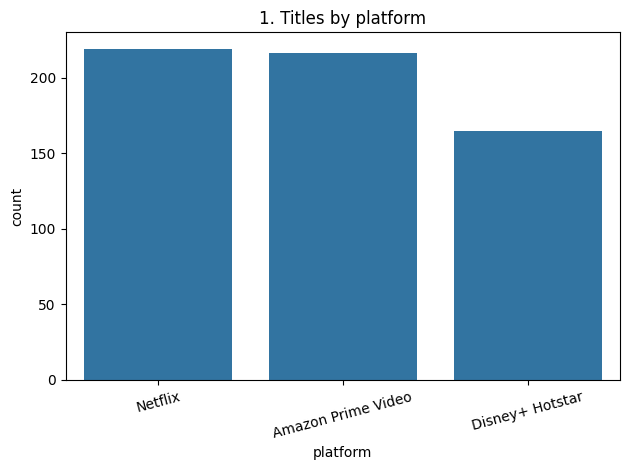

In [5]:
sns.countplot(data=df,x="platform"); plt.title("1. Titles by platform"); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

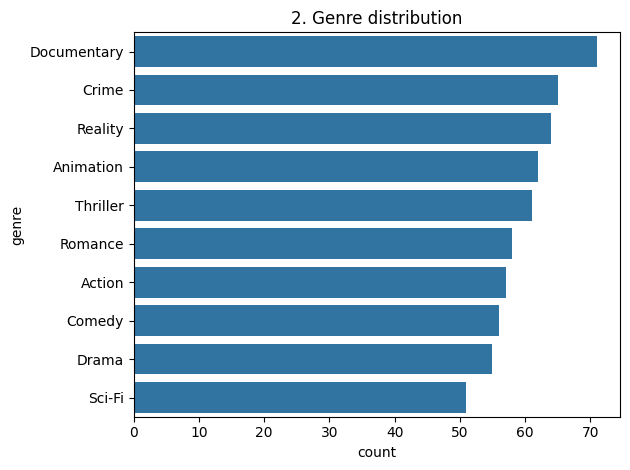

In [6]:
sns.countplot(data=df,y="genre",order=df.genre.value_counts().index); plt.title("2. Genre distribution"); plt.tight_layout(); plt.show()

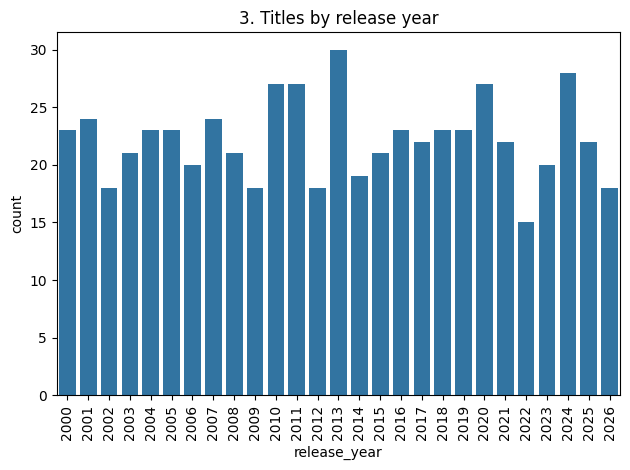

In [7]:
sns.countplot(data=df,x="release_year"); plt.title("3. Titles by release year"); plt.xticks(rotation=90); plt.tight_layout(); plt.show()

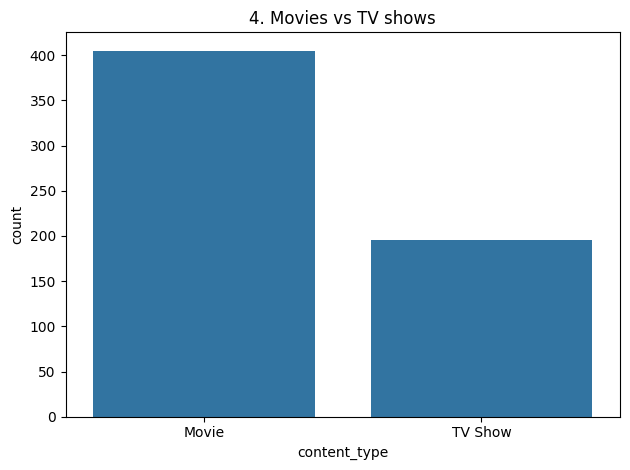

In [8]:
sns.countplot(data=df,x="content_type"); plt.title("4. Movies vs TV shows"); plt.tight_layout(); plt.show()

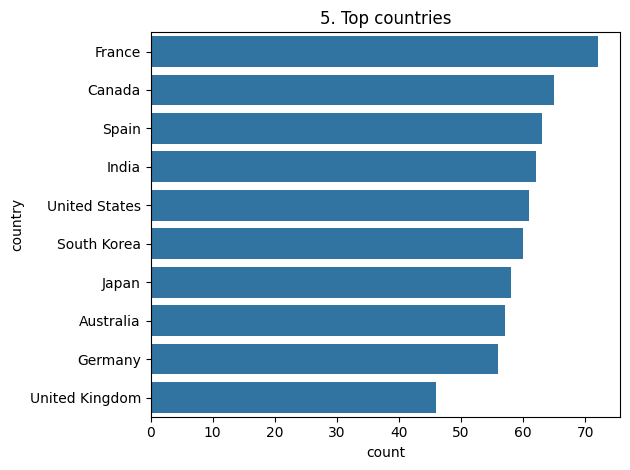

In [9]:
sns.countplot(data=df,y="country",order=df.country.value_counts().head(10).index); plt.title("5. Top countries"); plt.tight_layout(); plt.show()

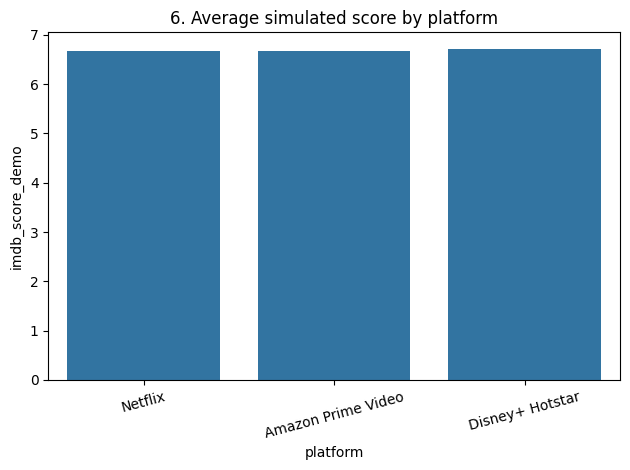

In [10]:
sns.barplot(data=df,x="platform",y="imdb_score_demo",errorbar=None); plt.title("6. Average simulated score by platform"); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

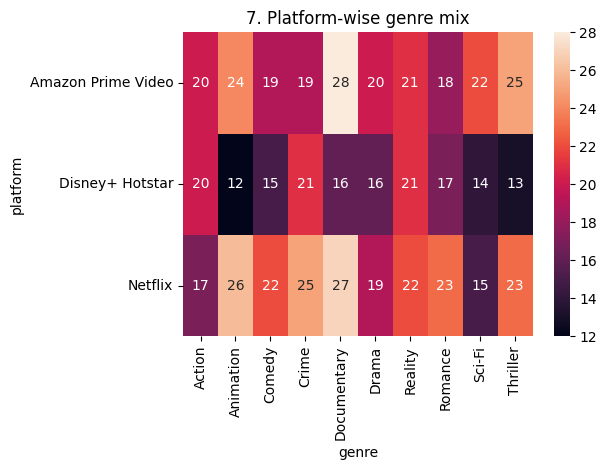

In [11]:
g=df.pivot_table(index="platform",columns="genre",values="content_id",aggfunc="count",fill_value=0); sns.heatmap(g,annot=True,fmt="d"); plt.title("7. Platform-wise genre mix"); plt.tight_layout(); plt.show()

## Three business observations to validate with real data
1. Compare genre mix by platform to identify categories that may be underrepresented.
2. Compare release-year patterns and recent-title share to assess catalog freshness.
3. Compare country representation to identify regions for deeper audience and rights research.

These are exploratory practice observations only because the dataset is synthetic.

In [12]:
print("Most common sample genre:", df.genre.value_counts().idxmax())
print("Most represented sample country:", df.country.value_counts().idxmax())
print("Recent releases (2020 onward):", (df.release_year>=2020).sum())

Most common sample genre: Documentary
Most represented sample country: France
Recent releases (2020 onward): 152
